# Cart Abandonment Pattern Analysis: Hungrly Checkout Funnel

**Role:** Product Analyst · **Stack:** SQL (SQLite) · Python (pandas, statsmodels, matplotlib) · Power BI

> **Business question:** *Where in the checkout flow are customers dropping off the most, and what should the product team fix first?*

**Context.** Hungrly is a (fictional) European food & grocery delivery app. Six months of clickstream data (Apr to Sep 2026, 185K sessions, 833K events) track every session through an 8-step checkout:

`Store/Menu View → Add to Cart → Cart View → Checkout Start → Delivery Details → Order Review → Payment → Order Placed`

**What this notebook does**
1. Data-quality checks on the event log
2. Funnel: where users leave, and what each exit screen costs
3. Segments: device / platform, category, time of day, new vs returning
4. Root cause at the worst step, with fees, promos, and basket size
5. Statistical validation (chi-square, logistic regression with controls)
6. Opportunity sizing in € and an A/B test plan for the top fix

All heavy lifting is done in SQL (`/sql`); Python handles statistics, modelling and charts.

In [1]:
import sqlite3, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import viz_style as vs
from run_sql_analysis import load_queries

vs.apply()
FIG = ROOT / "reports" / "figures"
con = sqlite3.connect(ROOT / "data" / "hungrly.db")
Q = load_queries()                       # every named query in /sql
sql = lambda name: pd.read_sql_query(Q[name], con)
pd.set_option("display.float_format", "{:,.2f}".format)
ANNUALISE = 365 / 183
print(f"{len(Q)} SQL queries loaded:", ", ".join(Q))

15 SQL queries loaded: funnel_overview, exit_screen_ranking, headline_kpis, weekly_trend, segment_step_exit_rates, segment_summary, hourly_profile, platform_payment_failures, review_exit_by_fee_ratio, review_exit_by_basket_size, review_exit_by_promo, checkout_start_login_wall, delivery_exit_by_eta, abandoned_value_by_step, opportunity_sizing


## 1. Data quality checks
Before trusting a funnel, make sure the event log is complete and ordered.

In [2]:
checks = pd.read_sql_query('''
SELECT 'sessions'                         AS check_name, COUNT(*) AS value FROM sessions
UNION ALL SELECT 'events',                 COUNT(*) FROM events
UNION ALL SELECT 'sessions without events', COUNT(*) FROM sessions s
          WHERE NOT EXISTS (SELECT 1 FROM events e WHERE e.session_id = s.session_id)
UNION ALL SELECT 'duplicate step events',   COUNT(*) FROM (
          SELECT session_id, event_name FROM events GROUP BY 1, 2 HAVING COUNT(*) > 1)
-- every session that reached step N must have all steps 1..N-1 (no skipped steps)
UNION ALL SELECT 'sessions with skipped steps', COUNT(*) FROM (
          SELECT e.session_id FROM events e JOIN funnel_steps f ON f.event_name = e.event_name
          GROUP BY e.session_id HAVING COUNT(*) <> MAX(e.step_number))
-- steps must be in chronological order
UNION ALL SELECT 'out-of-order timestamps', COUNT(*) FROM (
          SELECT step_number, event_ts,
                 LAG(event_ts) OVER (PARTITION BY session_id ORDER BY step_number, event_ts) AS prev_ts
          FROM events) WHERE event_ts < prev_ts
UNION ALL SELECT 'orders without order_placed event', COUNT(*) FROM orders o
          WHERE NOT EXISTS (SELECT 1 FROM events e WHERE e.session_id = o.session_id AND e.event_name = 'order_placed')
UNION ALL SELECT 'carts with negative / zero total', COUNT(*) FROM carts WHERE order_total <= 0
''', con)
checks

,check_name,value
0,sessions,185000
1,events,832990
2,sessions without events,0
3,duplicate step events,0
4,sessions with skipped steps,0
5,out-of-order timestamps,0
6,orders without order_placed event,0
7,carts with negative / zero total,0


All integrity checks return **0**: no orphan sessions, skipped steps, duplicates or time-travel. The funnel can be trusted.

In [3]:
df = pd.read_sql_query("SELECT * FROM vw_session_funnel", con, parse_dates=["session_start"])
kpi = sql("headline_kpis").iloc[0]
print(f"Sessions            {kpi.total_sessions:>12,.0f}")
print(f"Sessions with cart  {kpi.sessions_with_cart:>12,.0f}")
print(f"Orders              {kpi.orders:>12,.0f}")
print(f"Cart abandonment    {kpi.cart_abandonment_pct:>11.1f}%")
print(f"GMV (6 months)      {vs.eur(kpi.gmv_eur):>12}")
print(f"AOV                 {kpi.aov_eur:>11.2f}€")
print(f"Abandoned basket value (6m) {vs.eur(kpi.abandoned_gmv_eur)}")

Sessions                 185,000
Sessions with cart       126,378
Orders                    52,774
Cart abandonment           58.2%
GMV (6 months)            €1.86M
AOV                       35.21€
Abandoned basket value (6m) €2.30M


## 2. The funnel: where do customers leave?

In [4]:
funnel = sql("funnel_overview")
funnel

,step_number,step_label,sessions_reached,prev_step_sessions,step_conversion_pct,users_lost,step_dropoff_pct,pct_of_all_sessions
0,1,Store / Menu View,185000,NaN,NaN,NaN,NaN,100.00
1,2,Add to Cart,126378,"185,000.00",68.30,"58,622.00",31.70,68.30
2,3,Cart View,113203,"126,378.00",89.60,"13,175.00",10.40,61.20
3,4,Checkout Start,98608,"113,203.00",87.10,"14,595.00",12.90,53.30
4,5,Delivery Details,88902,"98,608.00",90.20,"9,706.00",9.80,48.10
5,6,Order Review,81225,"88,902.00",91.40,"7,677.00",8.60,43.90
6,7,Payment,58271,"81,225.00",71.70,"22,954.00",28.30,31.50
7,8,Order Placed,52774,"58,271.00",90.60,"5,497.00",9.40,28.50


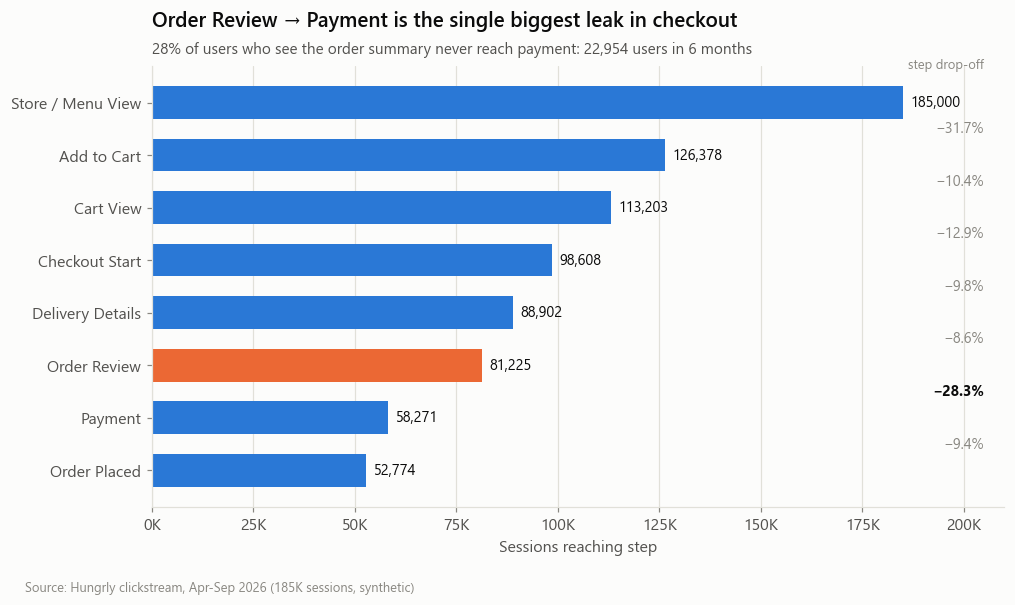

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.2))
f = funnel.copy()
worst = f.loc[f.step_number >= 3, "step_dropoff_pct"].idxmax()      # biggest in-checkout drop
colors = [vs.ORANGE if i == worst - 1 else vs.BLUE for i in f.index]  # colour the screen users leave from
y = np.arange(len(f))[::-1]
ax.barh(y, f.sessions_reached, color=colors, height=0.62)
ax.set_yticks(y, f.step_label)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}K"))
ax.grid(axis="y", visible=False)
for yi, (_, r) in zip(y, f.iterrows()):
    ax.text(r.sessions_reached + 1800, yi, f"{r.sessions_reached:,.0f}", va="center", fontsize=9.5, color=vs.INK)
    if r.step_number > 1:
        is_worst = r.name == worst
        ax.text(205_000, yi + 0.5, f"−{r.step_dropoff_pct:.1f}%",
                va="center", ha="right", fontsize=9.5,
                color=vs.INK if is_worst else vs.MUTED, fontweight="bold" if is_worst else "normal")
ax.set_xlim(0, 210_000)
ax.text(205_000, len(f) - 0.35, "step drop-off", ha="right", fontsize=8.5, color=vs.MUTED)
ax.set_title("Order Review → Payment is the single biggest leak in checkout")
vs.subtitle(ax, f"28% of users who see the order summary never reach payment: {f.loc[worst,'users_lost']:,.0f} users in 6 months")
ax.set_xlabel("Sessions reaching step")
vs.source_note(fig)
vs.save(fig, "01_checkout_funnel", FIG); plt.show()

**Reading the funnel.** Browsing → cart (−32%) is normal window-shopping. Inside checkout, though, one transition stands out:
**Order Review → Payment loses 28.3% of users**, 2–3× more than any other checkout step. The Order Review screen is the
first place users see the *full* price: delivery fee, service fee, small-order fee and whether their promo code worked.

In [6]:
exits = sql("exit_screen_ranking")
exits["abandoned_gmv_annual_eur"] = exits.abandoned_gmv_eur * ANNUALISE
exits

,step_number,exit_step,abandoned_carts,share_of_all_abandonments_pct,abandoned_gmv_eur,avg_basket_total_eur,rank_by_volume,abandoned_gmv_annual_eur
0,2,Add to Cart,13175,17.90,"432,931.00",32.86,3,"863,496.26"
1,3,Cart View,14595,19.80,"485,109.00",33.24,2,"967,567.13"
2,4,Checkout Start,9706,13.20,"321,004.00",33.07,4,"640,253.88"
3,5,Delivery Details,7677,10.40,"260,148.00",33.89,5,"518,874.43"
4,6,Order Review,22954,31.20,"603,559.00",26.29,1,"1,203,819.86"
5,7,Payment,5497,7.50,"194,961.00",35.47,6,"388,856.64"


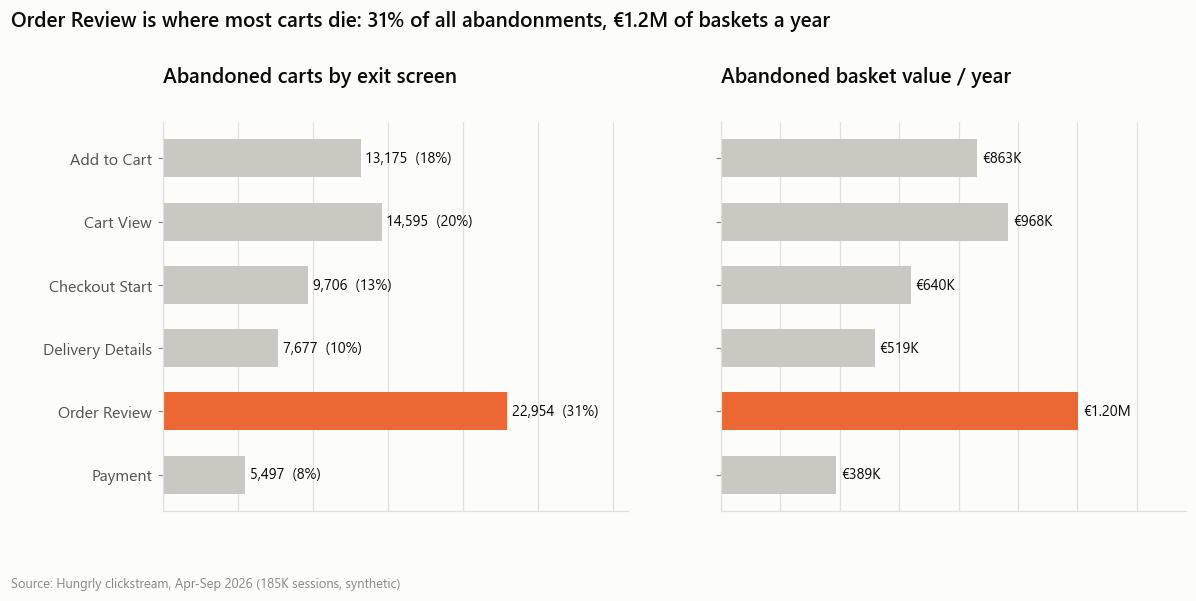

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
e = exits.sort_values("step_number", ascending=False)
c = [vs.ORANGE if s == "Order Review" else vs.CONTEXT for s in e.exit_step]
axes[0].barh(e.exit_step, e.abandoned_carts, color=c, height=0.6)
axes[0].set_title("Abandoned carts by exit screen")
for i, v in enumerate(e.abandoned_carts):
    axes[0].text(v + 300, i, f"{v:,.0f}  ({e.share_of_all_abandonments_pct.iloc[i]:.0f}%)", va="center", fontsize=9.5)
axes[0].set_xlim(0, e.abandoned_carts.max() * 1.35)
axes[1].barh(e.exit_step, e.abandoned_gmv_annual_eur, color=c, height=0.6)
axes[1].set_title("Abandoned basket value / year")
for i, v in enumerate(e.abandoned_gmv_annual_eur):
    axes[1].text(v + 15000, i, vs.eur(v), va="center", fontsize=9.5)
axes[1].set_xlim(0, e.abandoned_gmv_annual_eur.max() * 1.3)
for ax in axes:
    ax.grid(axis="y", visible=False); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: ""))
    ax.tick_params(axis="x", length=0)
fig.suptitle("Order Review is where most carts die: 31% of all abandonments, €1.2M of baskets a year",
             x=0.01, ha="left", fontsize=13.5, fontweight="semibold", y=1.1)
vs.source_note(fig)
vs.save(fig, "02_exit_screens", FIG); plt.show()

> **Abandoned basket value ≠ lost revenue.** Not every abandoned basket was ever going to convert. Sections 6–7 size what is
> realistically *recoverable* by benchmarking each problem segment against a healthy comparison group.

## 3. Segments: who drops off, and where?

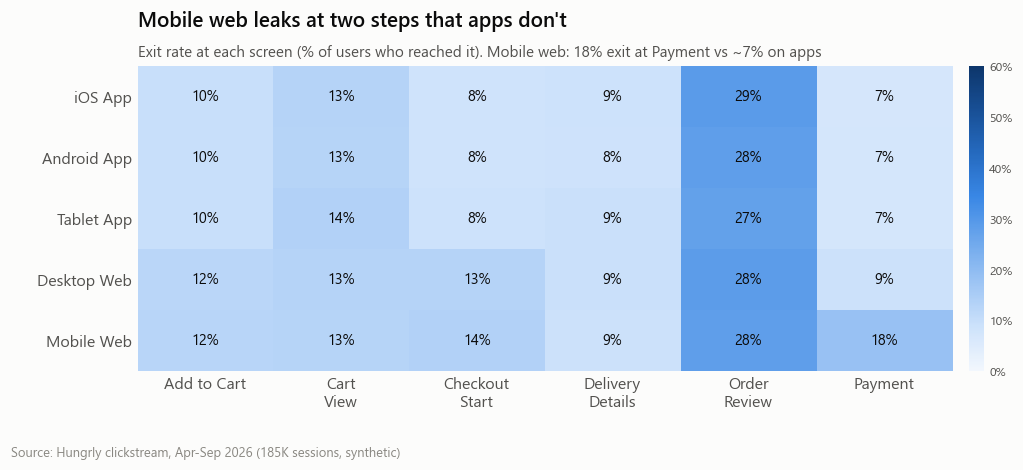

step_label,Add to Cart,Cart View,Checkout Start,Delivery Details,Order Review,Payment
segment,,,,,,
iOS App,9.60,13.00,8.20,8.60,28.60,6.70
Android App,9.60,12.70,8.10,8.40,28.00,7.00
Tablet App,9.60,13.50,8.50,9.00,27.20,7.00
Desktop Web,12.10,13.10,13.00,9.00,28.50,8.70
Mobile Web,12.20,12.70,13.50,8.80,28.10,18.20


In [8]:
seg = sql("segment_step_exit_rates")
def heat(dim, order=None, title="", sub="", name=None, figsize=(10, 3.6)):
    p = seg[seg.dimension == dim].pivot(index="segment", columns="step_label", values="exit_rate_pct")
    p = p[funnel.step_label.iloc[1:7].tolist()]
    if order: p = p.loc[order]
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(p.values, cmap=vs.BLUE_RAMP, aspect="auto", vmin=0, vmax=60)
    ax.set_xticks(range(p.shape[1]), [s.replace(" ", "\n", 1) if s.count(" ") == 1 else s for s in p.columns])
    ax.set_yticks(range(p.shape[0]), p.index)
    ax.grid(False); ax.tick_params(length=0)
    for sp in ax.spines.values(): sp.set_visible(False)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            v = p.values[i, j]
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9.5,
                    color="white" if v > 30 else vs.INK)
    ax.set_title(title); vs.subtitle(ax, sub)
    cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.outline.set_visible(False)
    cb.ax.yaxis.set_major_formatter(mtick.PercentFormatter()); cb.ax.tick_params(labelsize=8, length=0)
    vs.source_note(fig, y=-0.08)
    if name: vs.save(fig, name, FIG)
    plt.show()
    return p

heat("Platform", ["iOS App", "Android App", "Tablet App", "Desktop Web", "Mobile Web"],
     "Mobile web leaks at two steps that apps don't",
     "Exit rate at each screen (% of users who reached it). Mobile web: 18% exit at Payment vs ~7% on apps",
     "03_heatmap_platform")

In [9]:
summ = sql("segment_summary")
dev = summ[summ.dimension.isin(["Device", "Platform"])].copy()
# Wilson 95% CI so we don't over-read small segments
lo, hi = proportion_confint(dev.abandoned_carts, dev.carts, method="wilson")
dev["ci_95"] = [f"{100*a:.1f}–{100*b:.1f}%" for a, b in zip(lo, hi)]
dev[["dimension", "segment", "carts", "cart_abandonment_pct", "ci_95", "index_vs_overall", "abandoned_gmv_eur"]]

,dimension,segment,carts,cart_abandonment_pct,ci_95,index_vs_overall,abandoned_gmv_eur
8,Device,Desktop,12913,60.50,59.7–61.4%,104.00,"244,128.00"
9,Device,Mobile,109595,58.10,57.8–58.3%,100.00,"1,986,538.00"
10,Device,Tablet,3870,55.90,54.3–57.5%,96.00,"67,047.00"
11,Platform,Mobile Web,28830,64.50,63.9–65.0%,111.00,"590,212.00"
12,Platform,Desktop Web,12913,60.50,59.7–61.4%,104.00,"244,128.00"
13,Platform,iOS App,43400,56.00,55.5–56.5%,96.00,"754,894.00"
14,Platform,Tablet App,3870,55.90,54.3–57.5%,96.00,"67,047.00"
15,Platform,Android App,37365,55.50,55.0–56.0%,95.00,"641,433.00"


**Mobile vs laptop.** At the *device* level the gap looks small (Mobile 58.1% vs Desktop 60.5%). That's because "Mobile"
mixes great native apps with a weak mobile website. Split by **platform** and the story appears: **Mobile Web abandons
64.5% of carts vs 56% on iOS**, driven by the Payment step (no Apple/Google Pay, 3-D Secure redirect) and the login wall.

In [10]:
pay = sql("platform_payment_failures")
mw = df[df.furthest_step >= 7].assign(mweb=lambda d: d.platform.eq("Mobile Web"),
                                      exited=lambda d: d.furthest_step.eq(7))
mw = mw[mw.platform.isin(["Mobile Web", "iOS App", "Android App"])]
ct = pd.crosstab(mw.mweb, mw.exited)
chi2, p, dof, _ = chi2_contingency(ct)
print(f"Payment-step exit, Mobile Web vs native apps: chi2={chi2:,.0f}, p={p:.1e}")
pay.head(6)

Payment-step exit, Mobile Web vs native apps: chi2=1,411, p=1.0e-308


,platform,payment_method,reached_payment,payment_error_pct,payment_exit_pct
0,Mobile Web,Card,9001,23.80,21.20
1,Mobile Web,PayPal,3516,7.00,10.60
2,Desktop Web,Card,3691,10.40,9.50
3,Tablet App,Card,573,10.10,8.60
4,Android App,Card,5805,9.80,8.40
5,Android App,PayPal,2864,7.80,8.40


Card payments on mobile web fail **24%** of the time on first attempt (vs 3% for wallet pay) and 21% of those users leave. The difference is significant (p ≪ 0.001).

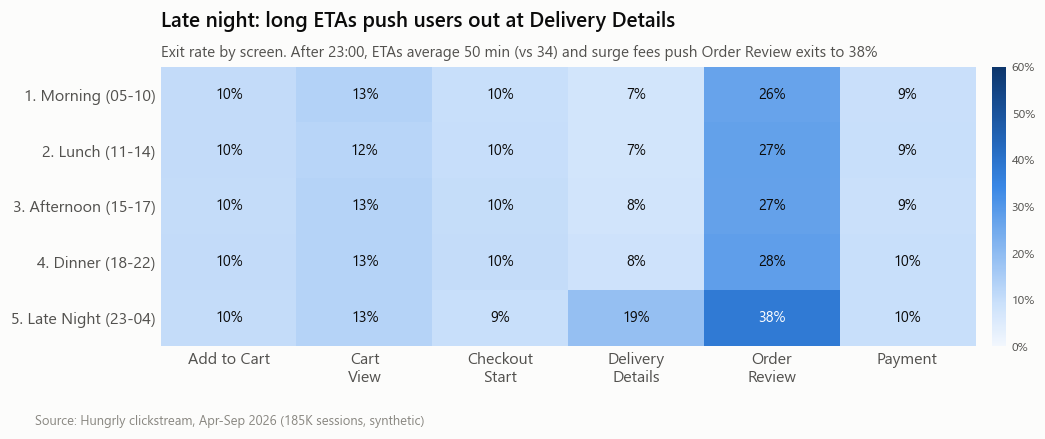

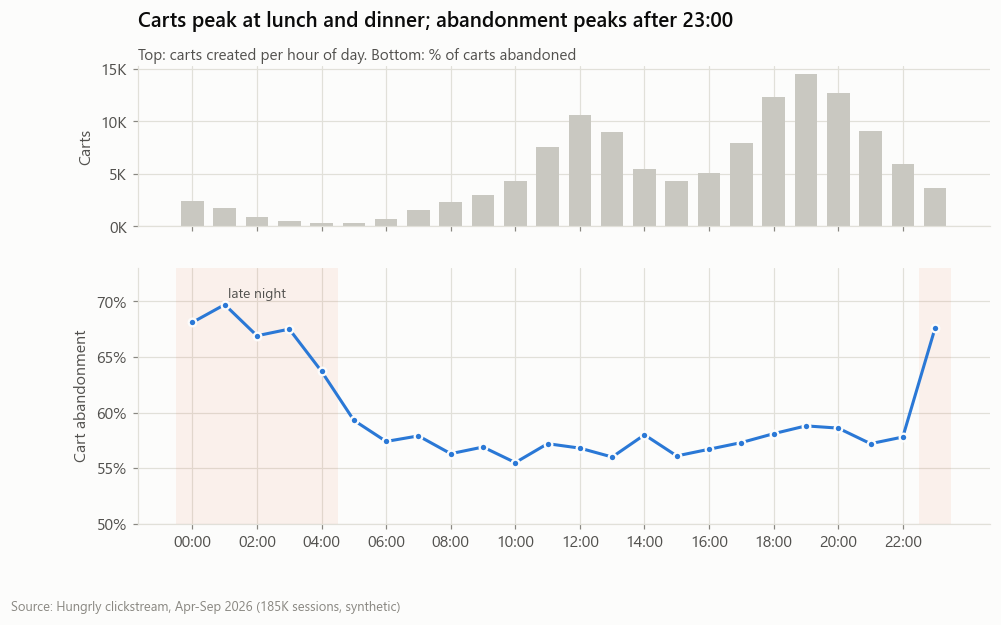

In [11]:
heat("Time of Day", None, "Late night: long ETAs push users out at Delivery Details",
     "Exit rate by screen. After 23:00, ETAs average 50 min (vs 34) and surge fees push Order Review exits to 38%",
     "04_heatmap_time_of_day", figsize=(10, 3.3))

hourly = sql("hourly_profile")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.4), sharex=True, gridspec_kw={"height_ratios": [1, 1.6]})
a1.bar(hourly.session_hour, hourly.carts, color=vs.CONTEXT, width=0.7)
a1.set_ylabel("Carts"); a1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}K"))
a1.set_title("Carts peak at lunch and dinner; abandonment peaks after 23:00")
vs.subtitle(a1, "Top: carts created per hour of day. Bottom: % of carts abandoned")
night = hourly.session_hour.isin([23, 0, 1, 2, 3, 4])
a2.axvspan(-0.5, 4.5, color=vs.ORANGE, alpha=0.08, lw=0); a2.axvspan(22.5, 23.5, color=vs.ORANGE, alpha=0.08, lw=0)
a2.plot(hourly.session_hour, hourly.cart_abandonment_pct, color=vs.BLUE, marker="o", ms=5,
        markeredgecolor=vs.SURFACE, markeredgewidth=1.5)
a2.set_ylabel("Cart abandonment"); a2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
a2.set_xticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
a2.text(2, hourly.cart_abandonment_pct.max() + 0.6, "late night", ha="center", color=vs.INK_2, fontsize=9)
a2.set_ylim(50, 73)
vs.source_note(fig)
vs.save(fig, "05_hourly_profile", FIG); plt.show()

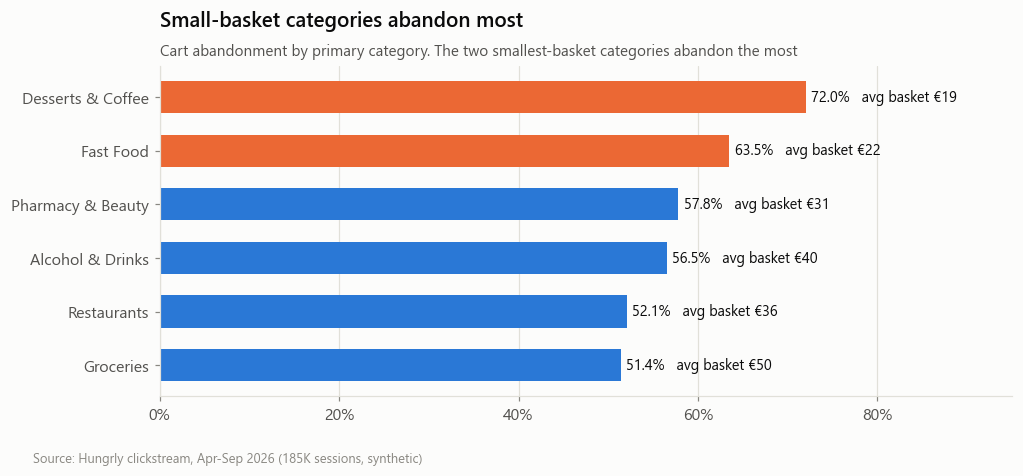

In [12]:
cat = summ[summ.dimension == "Category"].sort_values("cart_abandonment_pct")
fig, ax = plt.subplots(figsize=(10, 3.9))
c = [vs.ORANGE if s in ("Desserts & Coffee", "Fast Food") else vs.BLUE for s in cat.segment]
ax.barh(cat.segment, cat.cart_abandonment_pct, color=c, height=0.6)
for i, (_, r) in enumerate(cat.iterrows()):
    ax.text(r.cart_abandonment_pct + 0.6, i, f"{r.cart_abandonment_pct:.1f}%   avg basket €{r.avg_basket_eur:.0f}",
            va="center", fontsize=9.5)
ax.set_xlim(0, 95); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Small-basket categories abandon most")
vs.subtitle(ax, "Cart abandonment by primary category. The two smallest-basket categories abandon the most")
vs.source_note(fig)
vs.save(fig, "06_category", FIG); plt.show()

Desserts & Coffee (72%) and Fast Food (64%) abandon far more than Groceries (51%). **Is it the category, or the basket size?**
Small baskets attract a proportionally larger fee. Section 5 tests this with a regression that controls for fees.

## 4. Root cause at Order Review: fee shock & broken promo promises

In [13]:
fee = sql("review_exit_by_fee_ratio"); basket = sql("review_exit_by_basket_size"); promo = sql("review_exit_by_promo")
display(fee); display(basket); display(promo)

,fee_ratio_band,reached_review,exited_at_review,review_exit_pct,avg_subtotal_eur,avg_fees_eur
0,01. <5%,4351,460,10.60,79.10,3.00
1,02. 5-10%,15479,1843,11.90,40.03,2.56
2,03. 10-15%,18943,3574,18.90,34.86,4.39
3,04. 15-20%,16220,3757,23.20,24.35,4.17
4,05. 20-30%,10657,3360,31.50,18.88,4.43
5,06. 30-40%,3277,1424,43.50,14.51,4.99
6,07. 40%+,12298,8536,69.40,10.37,6.91


,basket_band,reached_review,pct_with_small_order_fee,avg_fees_eur,avg_fee_ratio_pct,review_exit_pct
0,01. < EUR 10,4833,100.00,7.23,90.60,74.40
1,02. EUR 10-15,12049,100.00,5.77,47.50,55.90
2,03. EUR 15-20,12600,0.00,3.34,19.30,28.10
3,04. EUR 20-30,20591,0.00,3.78,15.40,20.20
4,05. EUR 30-50,21433,0.00,4.23,11.30,17.20
5,06. EUR 50+,9719,0.00,3.79,6.00,12.80


,promo_status,reached_review,exited_at_review,review_exit_pct,abandoned_gmv_eur
0,Failed - Min Spend Not Met,4713,3388,71.90,"63,050.00"
1,Failed - Expired,2092,1051,50.20,"36,465.00"
2,Failed - Category Excluded,1809,909,50.20,"32,949.00"
3,No Promo,57813,14874,25.70,"401,872.00"
4,Applied,14798,2732,18.50,"69,223.00"


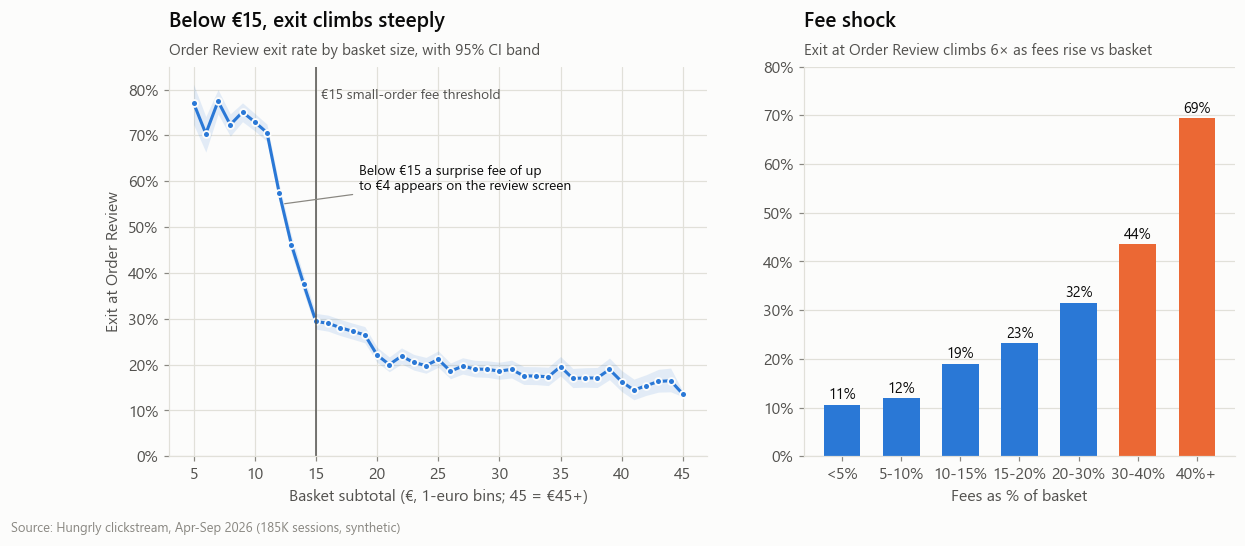

In [14]:
rev = df[df.furthest_step >= 6].copy()
rev["exit_review"] = rev.furthest_step.eq(6)
rev["bin"] = np.floor(rev.cart_subtotal).clip(5, 45)
curve = rev.groupby("bin").agg(n=("exit_review", "size"), rate=("exit_review", "mean")).reset_index()
lo, hi = proportion_confint(curve.rate * curve.n, curve.n, method="wilson")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
a1.fill_between(curve.bin, lo * 100, hi * 100, color=vs.BLUE, alpha=0.12, lw=0)
a1.plot(curve.bin, curve.rate * 100, color=vs.BLUE, marker="o", ms=4.5, markeredgecolor=vs.SURFACE, markeredgewidth=1.2)
a1.axvline(15, color=vs.INK_2, lw=1)
a1.text(15.4, 78, "€15 small-order fee threshold", fontsize=9, color=vs.INK_2)
a1.annotate("Below €15 a surprise fee of up\nto €4 appears on the review screen", xy=(12.2, 55), xytext=(18.5, 58),
            fontsize=9, color=vs.INK, arrowprops=dict(arrowstyle="-", color=vs.MUTED, lw=0.8))
a1.set_xlabel("Basket subtotal (€, 1-euro bins; 45 = €45+)"); a1.set_ylabel("Exit at Order Review")
a1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); a1.set_ylim(0, 85)
a1.set_title("Below €15, exit climbs steeply"); vs.subtitle(a1, "Order Review exit rate by basket size, with 95% CI band")

f2 = fee.copy(); f2["band"] = f2.fee_ratio_band.str[4:]
c = [vs.ORANGE if b in ("30-40%", "40%+") else vs.BLUE for b in f2.band]
a2.bar(f2.band, f2.review_exit_pct, color=c, width=0.62)
for i, v in enumerate(f2.review_exit_pct):
    a2.text(i, v + 1.2, f"{v:.0f}%", ha="center", fontsize=9.5)
a2.set_xlabel("Fees as % of basket"); a2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
a2.set_ylim(0, 80); a2.grid(axis="x", visible=False)
a2.set_title("Fee shock"); vs.subtitle(a2, "Exit at Order Review climbs 6× as fees rise vs basket")
vs.source_note(fig)
vs.save(fig, "07_fee_shock", FIG); plt.show()

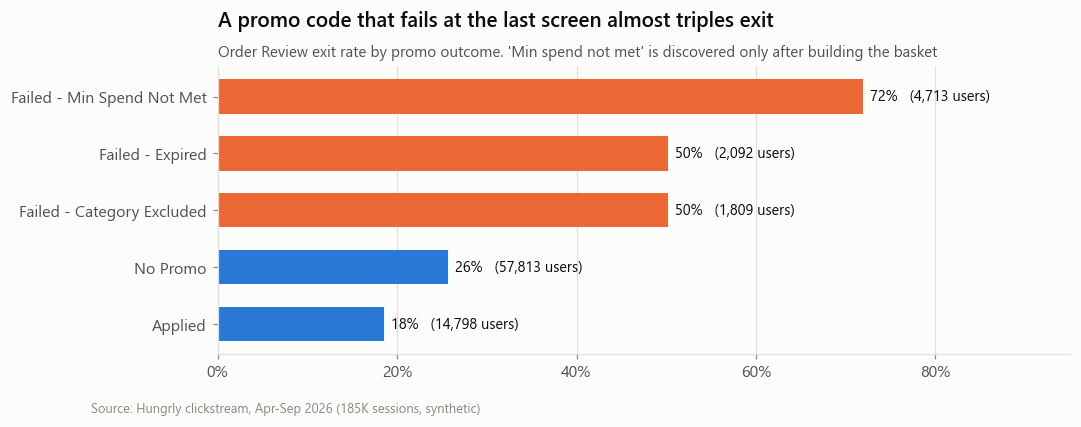

In [15]:
p2 = promo.sort_values("review_exit_pct")
fig, ax = plt.subplots(figsize=(10, 3.4))
c = [vs.ORANGE if s.startswith("Failed") else vs.BLUE for s in p2.promo_status]
ax.barh(p2.promo_status, p2.review_exit_pct, color=c, height=0.6)
for i, (_, r) in enumerate(p2.iterrows()):
    ax.text(r.review_exit_pct + 0.8, i, f"{r.review_exit_pct:.0f}%   ({r.reached_review:,} users)", va="center", fontsize=9.5)
ax.set_xlim(0, 95); ax.grid(axis="y", visible=False); ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("A promo code that fails at the last screen almost triples exit")
vs.subtitle(ax, "Order Review exit rate by promo outcome. 'Min spend not met' is discovered only after building the basket")
vs.source_note(fig)
vs.save(fig, "08_promo_failures", FIG); plt.show()

**Two root causes at Order Review**

* **Fee shock.** Exit rises from **11%** when fees are under 10% of the basket to **69%** when they exceed 40%. Baskets under the
  **€15 small-order threshold** (which add a fee of up to €4) exit at **56–74%** vs 28% for €15–20 baskets, and users learn about
  that fee only on the review screen.
* **Broken promise.** Users whose promo failed exit at **50–72%** vs **26%** with no promo. "Min spend not met" is the worst: the
  user was told about a discount, built a basket, and only then learned it doesn't qualify.

## 5. Statistical validation: is it really fees, or just the category/device mix?
Logistic regression on everyone who reached Order Review (n ≈ 81K). Outcome = exited at Order Review.

In [16]:
m = rev.assign(
    exit_review=rev.exit_review.astype(int),
    fee_ratio_10pp=rev.fee_ratio.clip(upper=0.6) * 10,            # per +10 pp of fees vs basket
    small_order_fee=(rev.small_order_fee > 0).astype(int),
    promo_failed=rev.promo_status.str.startswith("Failed").astype(int),
    promo_applied=rev.promo_status.eq("Applied").astype(int),
    late_night=rev.time_of_day.str.startswith("5").astype(int),
)
naive = smf.logit("exit_review ~ C(primary_category, Treatment('Groceries'))", data=m).fit(disp=0)
full = smf.logit(
    "exit_review ~ fee_ratio_10pp + promo_failed + promo_applied + is_plus_member + is_new_user + late_night"
    " + C(platform, Treatment('iOS App')) + C(primary_category, Treatment('Groceries'))", data=m).fit(disp=0)

def odds(model):
    ci = np.exp(model.conf_int()); out = pd.DataFrame({"odds_ratio": np.exp(model.params), "ci_low": ci[0], "ci_high": ci[1], "p_value": model.pvalues})
    return out.drop("Intercept")

cmp = pd.DataFrame({"OR_category_only": odds(naive).odds_ratio, "OR_with_controls": odds(full).odds_ratio}).dropna()
cmp.index = cmp.index.str.replace(r"C\(primary_category, Treatment\('Groceries'\)\)\[T\.", "", regex=True).str.rstrip("]")
print(f"Full model pseudo-R² = {full.prsquared:.3f}, n = {int(full.nobs):,}")
cmp.round(2)

Full model pseudo-R² = 0.188, n = 81,225


,OR_category_only,OR_with_controls
Alcohol & Drinks,1.76,1.00
Desserts & Coffee,6.37,1.04
Fast Food,3.49,1.00
Pharmacy & Beauty,2.34,0.97
Restaurants,1.35,1.01


**Confounding uncovered.** On its own, *Desserts & Coffee* looks like a 6× higher-risk category. Once fees and promos are
controlled for, its odds ratio collapses to **≈1**. **The category isn't the problem; the fee-to-basket ratio is.** That changes the fix:
not "improve the desserts menu" but "fix how fees are communicated and structured for small baskets".

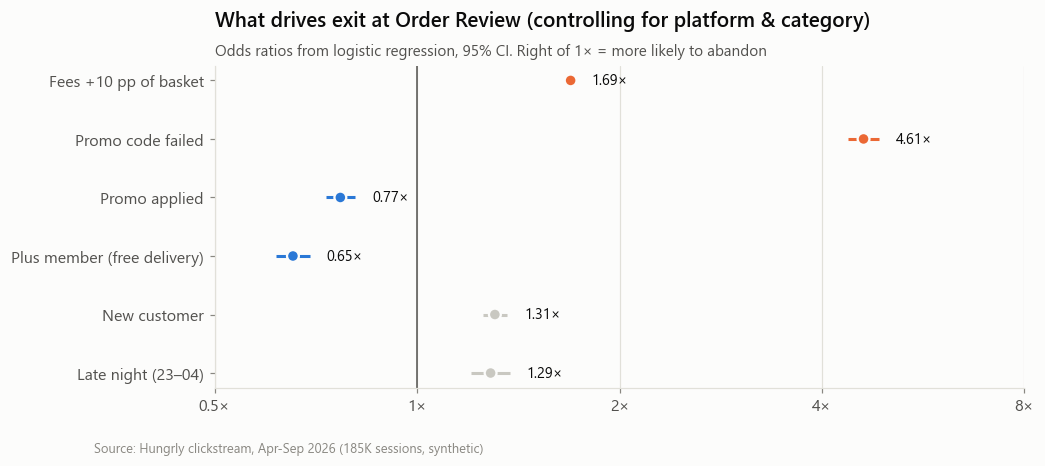

In [17]:
o = odds(full)
labels = {"fee_ratio_10pp": "Fees +10 pp of basket", "promo_failed": "Promo code failed", "promo_applied": "Promo applied",
          "is_plus_member": "Plus member (free delivery)", "is_new_user": "New customer", "late_night": "Late night (23–04)"}
o = o.loc[[k for k in labels]].rename(index=labels).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.axvline(1, color=vs.INK_2, lw=1)
col = [vs.ORANGE if v > 1.5 else (vs.BLUE if v < 1 else vs.CONTEXT) for v in o.odds_ratio]
ax.hlines(range(len(o)), o.ci_low, o.ci_high, color=col, lw=2)
ax.scatter(o.odds_ratio, range(len(o)), color=col, s=60, zorder=3, edgecolor=vs.SURFACE, linewidth=1.5)
for i, (_, r) in enumerate(o.iterrows()):
    ax.text(r.ci_high * 1.06, i, f"{r.odds_ratio:.2f}×", va="center", fontsize=9.5)
ax.set_xscale("log"); ax.set_xticks([0.5, 1, 2, 4, 8], ["0.5×", "1×", "2×", "4×", "8×"]); ax.minorticks_off()
ax.set_yticks(range(len(o)), o.index); ax.grid(axis="y", visible=False)
ax.set_title("What drives exit at Order Review (controlling for platform & category)")
vs.subtitle(ax, "Odds ratios from logistic regression, 95% CI. Right of 1× = more likely to abandon")
vs.source_note(fig)
vs.save(fig, "09_drivers_odds_ratios", FIG); plt.show()

Every +10 pp of fees (relative to basket) multiplies the odds of abandoning by **~1.7×**; a failed promo by **~4.5×**.
Plus members (free delivery) are *less* likely to leave, which is direct evidence that fees, not intent, drive the exit.

### Other leaks

In [18]:
login = sql("checkout_start_login_wall"); eta = sql("delivery_exit_by_eta")
display(login); display(eta)
nw = m_login = df[(df.furthest_step >= 4) & (df.is_new_user == 1)].assign(web=lambda d: d.platform.str.endswith("Web"),
                                                                         ex=lambda d: d.furthest_step.eq(4))
z, p = proportions_ztest([nw[nw.web].ex.sum(), nw[~nw.web].ex.sum()], [nw.web.sum(), (~nw.web).sum()])
print(f"New users exit at Checkout Start: web {nw[nw.web].ex.mean():.1%} vs app {nw[~nw.web].ex.mean():.1%}  (z={z:.1f}, p={p:.1e})")

,channel,customer_type,reached_checkout_start,checkout_start_exit_pct
0,Web,New,7841,32.80
1,App,New,16190,11.50
2,App,Returning,50472,7.10
3,Web,Returning,24105,7.00


,eta_band,reached_delivery_details,delivery_exit_pct
0,01. <30 min,24901,6.30
1,02. 30-39 min,30482,6.70
2,03. 40-49 min,21131,9.40
3,04. 50-59 min,9215,14.80
4,05. 60+ min,3173,22.30


New users exit at Checkout Start: web 32.8% vs app 11.5%  (z=39.8, p=0.0e+00)


* **Login wall:** new web users must create an account at Checkout Start: **33% leave** vs 11.5% of new app users.
* **Long ETAs:** at 60+ min ETA, 22% leave at Delivery Details vs 6% under 30 min, concentrated late at night.

## 6. Opportunity sizing: what is each fix worth?

For each leak: *excess exit rate vs a healthy benchmark × users affected × downstream conversion × average order value*,
annualised. **Full closure** is the ceiling; **30% closure** is the planning case a PM can commit to.

In [19]:
opp = sql("opportunity_sizing")
opp[["opportunity", "step", "sessions_affected_6m", "segment_exit_pct", "benchmark_exit_pct", "relative_risk",
     "orders_recoverable_6m_full", "gmv_annual_full_closure_eur", "gmv_annual_30pct_closure_eur"]]

,opportunity,step,sessions_affected_6m,segment_exit_pct,benchmark_exit_pct,relative_risk,orders_recoverable_6m_full,gmv_annual_full_closure_eur,gmv_annual_30pct_closure_eur
0,Fee shock,Order Review,42452,40.20,11.60,3.46,"11,000.00","497,030.00","149,109.00"
1,Failed promo codes,Order Review,8614,62.10,25.70,2.41,"2,847.00","155,249.00","46,575.00"
2,Mobile-web payment friction,Payment,12517,18.20,6.80,2.68,"1,426.00","99,984.00","29,995.00"
3,Long delivery ETAs,Delivery Details,12388,16.70,6.50,2.55,798.00,"58,351.00","17,505.00"
4,Forced sign-up (no guest checkout),Checkout Start,7841,32.80,11.50,2.84,877.00,"57,761.00","17,328.00"


In [20]:
# De-duplicated, model-based view for Order Review (fee & promo segments overlap: small baskets fail min-spend)
base = full.predict(m).sum()
fix_promo = full.predict(m.assign(promo_failed=0)).sum()
no_small_fee_ratio = ((m.total_fees - m.small_order_fee) / m.cart_subtotal).clip(upper=0.6) * 10
fix_fee = full.predict(m.assign(fee_ratio_10pp=no_small_fee_ratio)).sum()
fix_both = full.predict(m.assign(promo_failed=0, fee_ratio_10pp=no_small_fee_ratio)).sum()
down = df[df.furthest_step >= 7].converted.mean()
aov_r = m.order_total.mean()
scen = pd.DataFrame({
    "scenario": ["Promo failures resolved", "Small-order fee surprise removed", "Both"],
    "fewer_review_exits_6m": [base - fix_promo, base - fix_fee, base - fix_both],
})
scen["extra_orders_6m"] = scen.fewer_review_exits_6m * down
scen["gmv_annual_eur"] = scen.extra_orders_6m * aov_r * ANNUALISE
scen.round(0)

,scenario,fewer_review_exits_6m,extra_orders_6m,gmv_annual_eur
0,Promo failures resolved,"2,568.00","2,326.00","151,707.00"
1,Small-order fee surprise removed,868.00,786.00,"51,281.00"
2,Both,"3,476.00","3,148.00","205,347.00"


**Cross-check.** The SQL gap-closure numbers can double count (a small basket can be in both the fee and the promo segment)
and benchmark against carts that differ in other ways. The regression isolates the two levers product can actually pull:
resolving promo failures (≈ €152K / yr) and removing the small-order-fee surprise (≈ €51K / yr), **≈ €205K / yr together**.
That lands right next to the **30% planning case for fixes #1 + #2 (€196K)**, so the planning case is a realistic target, not a stretch.

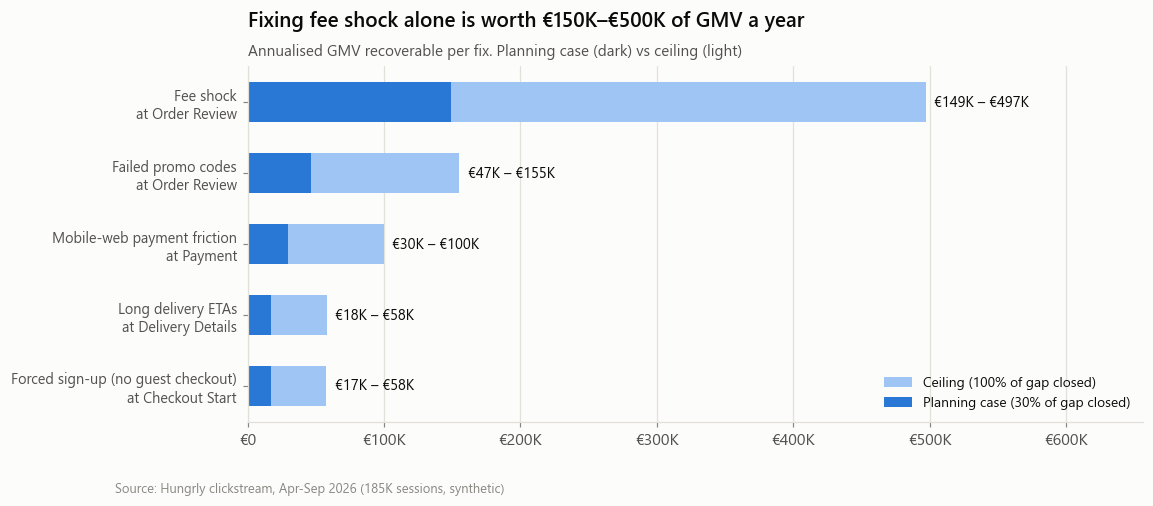

In [21]:
o2 = opp.sort_values("gmv_annual_full_closure_eur")
fig, ax = plt.subplots(figsize=(10.5, 4.2))
yy = np.arange(len(o2))
ax.barh(yy, o2.gmv_annual_full_closure_eur, color=vs.LIGHT_BLUE, height=0.56, label="Ceiling (100% of gap closed)")
ax.barh(yy, o2.gmv_annual_30pct_closure_eur, color=vs.BLUE, height=0.56, label="Planning case (30% of gap closed)")
for i, (_, r) in enumerate(o2.iterrows()):
    ax.text(r.gmv_annual_full_closure_eur + 6000, i, f"{vs.eur(r.gmv_annual_30pct_closure_eur)} – {vs.eur(r.gmv_annual_full_closure_eur)}",
            va="center", fontsize=9.5)
ax.set_yticks(yy, [f"{a}\nat {s}" for a, s in zip(o2.opportunity, o2.step)], fontsize=9.5)
ax.set_xlim(0, o2.gmv_annual_full_closure_eur.max() * 1.32); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: vs.eur(v)))
ax.legend(loc="lower right", fontsize=9)
ax.set_title("Fixing fee shock alone is worth €150K–€500K of GMV a year")
vs.subtitle(ax, "Annualised GMV recoverable per fix. Planning case (dark) vs ceiling (light)")
vs.source_note(fig)
vs.save(fig, "10_opportunity_sizing", FIG); plt.show()

## 7. How to prove it: A/B test design for the #1 fix

**Hypothesis:** Showing an all-in price (fees + promo eligibility) on the **cart** screen, plus an "add €X to skip the small-order
fee" nudge, reduces Order Review exits without just moving them earlier.

* **Primary metric:** cart → order conversion (captures exits that move upstream)
* **Secondary:** Order Review exit rate, AOV (should *rise* from the top-up nudge), basket size distribution around €15
* **Guardrails:** fee revenue per order, cart → checkout start rate, support contacts

In [22]:
p0 = df[df.furthest_step >= 2].converted.mean()
daily_carts = (df.furthest_step >= 2).sum() / 183
rows = []
for mde in [0.010, 0.015, 0.020, 0.030]:
    es = proportion_effectsize(p0 + mde, p0)
    n = NormalIndPower().solve_power(effect_size=es, alpha=0.05, power=0.8, ratio=1)
    rows.append({"min_detectable_lift_pp": mde * 100, "carts_per_arm": int(np.ceil(n)),
                 "days_at_50/50_split": int(np.ceil(2 * n / daily_carts))})
print(f"Baseline cart→order conversion {p0:.1%}; ~{daily_carts:,.0f} carts/day")
pd.DataFrame(rows)

Baseline cart→order conversion 41.8%; ~691 carts/day


,min_detectable_lift_pp,carts_per_arm,days_at_50/50_split
0,1.00,38303,111
1,1.50,17049,50
2,2.00,9604,28
3,3.00,4280,13


At ~690 carts/day, a **+2 pp** lift needs ~**4 weeks** at a 50/50 split; +1.5 pp needs ~7 weeks. Recommendation: target
**+2 pp** over 4 full weeks (covers weekday/weekend cycles). Restricting the test to baskets under €20 would raise the expected
effect and shorten the run.

## 8. Recommendations for the product team

| # | Fix | Step | Evidence | Annual GMV (30% → 100%) | Effort |
|---|---|---|---|---|---|
| 1 | **All-in price on the cart screen** + "add €X to skip the small-order fee" progress bar | Order Review | Exit 11% → 69% as fees rise; €15 cliff; OR 1.7× per +10 pp | **€149K – €497K** | Medium |
| 2 | **Validate promo codes in the cart**, show min-spend progress ("€4.20 more to unlock 20% off") | Order Review | Failed promo exit 62% vs 26%; OR ≈ 4.5× | **€47K – €155K** | Low |
| 3 | **Enable Apple Pay / Google Pay on mobile web**, inline 3-DS | Payment | Card errors 24% on m-web; exit 18% vs 7% on apps | **€30K – €100K** | Medium |
| 4 | **Show ETA on the store page**, suggest scheduled delivery late at night | Delivery Details | Exit 6% (<30 min) → 22% (60+ min) | **€18K – €58K** | Low |
| 5 | **Guest checkout** for new web users (account after order) | Checkout Start | New web users exit 33% vs 11.5% on app | **€17K – €58K** | Medium |

**Bottom line:** start with #1 and #2. They are the same root cause (users discover the real price at the last screen),
they're on the same screen, and together they account for more than two-thirds of the recoverable value.

In [23]:
con.close()